# 01 · EDA: Policies
**BEV vs. ICE Motor Property Insurance**

**Purpose:** understand the policy portfolio (the exposure base) and identify **confounders**: rating factors whose distribution differs by powertrain and which must therefore be controlled for in the GLM stage.

**Input:** `data/processed/policies_cleaned.rds`, written by `src/01_clean_datasets.R` (run it first). All cleaning happens in that script; this notebook only adds EDA-only derived columns (§1.4).

**Questions**
1. What is the BEV / Hybrid / ICE mix by policy count and by earned exposure?
2. Do BEVs differ systematically in vehicle value or vehicle age?
3. Do BEV drivers differ in age, licence tenure, gender or district?
4. Does the current premium already differ by powertrain?

**Data source:** the dataset is synthetic. It was provided by the seminar supervisors, Anat Elad and Irena Veyro, as two raw extracts: `policies_raw.csv` and `claims_raw.csv`.

## 1. Setup & Data Ingestion

In [1]:
# suppressWarnings hides "package built under R 4.5.x" notices
suppressWarnings(suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(lubridate)
}))

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 110,
        dplyr.summarise.inform = FALSE)
theme_set(theme_minimal(base_size = 12))

pt_colours <- c(BEV = "#1b9e77", Hybrid = "#7570b3", ICE = "#d95f02")

# Path to a file in data/processed/; works from notebooks/ or the repository root
processed_path <- function(file) {
  path <- file.path(c("../data/processed", "data/processed"), file) |>
    keep(file.exists) |>
    first()
  stopifnot(!is.na(path))
  path
}

# Summary statistics of a numeric variable by powertrain
summarise_by_powertrain <- function(data, var) {
  data |>
    filter(!is.na({{ var }})) |>
    group_by(Powertrain) |>
    summarise(n      = n(),
              mean   = mean({{ var }}),
              median = median({{ var }}),
              p25    = quantile({{ var }}, 0.25),
              p75    = quantile({{ var }}, 0.75))
}

# Column-percentage cross-tab: share of each powertrain's policies per level of `var`
share_table <- function(data, var) {
  data |>
    count(Powertrain, {{ var }}) |>
    group_by(Powertrain) |>
    mutate(share = percent(n / sum(n), accuracy = 0.1)) |>
    ungroup() |>
    select(-n) |>
    pivot_wider(names_from = Powertrain, values_from = share, values_fill = "0.0%")
}

### 1.1 Load and inspect structure
`policies_cleaned.rds` keeps the R types: dates are `Date`, `Powertrain` is a factor (ICE / Hybrid / BEV) and `Premium` is numeric.

In [2]:
policies_cleaned <- read_rds(processed_path("policies_cleaned.rds"))

cat("Rows:", nrow(policies_cleaned), "| Columns:", ncol(policies_cleaned), "\n\n")
glimpse(policies_cleaned)

Rows: 38309 | Columns: 13 



Rows: 38,309
Columns: 13
$ Policy_ID      <chr> "P2000004", "P2000010", "P2000022", "P2000030", "P20001…
$ Start_Date     <date> 2024-12-25, 2024-04-18, 2024-09-14, 2024-01-10, 2024-0…
$ End_Date       <date> 2025-12-24, 2025-01-25, 2025-09-13, 2025-01-09, 2024-1…
$ exposure       <dbl> 0.9993155, 0.7748118, 0.9993155, 1.0020534, 0.1998631, …
$ District       <chr> "North", "North", "Center", "Center", "Tel Aviv", "Haif…
$ Gender         <chr> "Male", "Female", "Male", "Female", "Male", "Male", "Ma…
$ Driver_Age     <dbl> 60, 45, 52, 38, 63, 62, 50, 18, 41, 65, 33, 35, 55, 55,…
$ License_Tenure <dbl> 43, 26, 35, 21, 42, 44, 30, 0, 22, 45, 15, 15, 35, 37, …
$ Powertrain     <fct> ICE, ICE, ICE, ICE, BEV, BEV, ICE, Hybrid, ICE, ICE, BE…
$ Fuel_Detail    <chr> "Petrol", "Petrol", "Petrol", "Petrol", "BEV", "BEV", "…
$ Vehicle_Age    <dbl> 6, 5, 5, 7, 2, 1, 5, 2, 6, 13, 5, 7, 19, 9, 4, 7, 2, 7,…
$ Vehicle_Value  <dbl> 76200, 90300, 50200, 50400, 221000, 123500, 125900, 139…
$ Premium      

In [3]:
summary(select(policies_cleaned, where(is.numeric)))

    exposure         Driver_Age    License_Tenure   Vehicle_Age    
 Min.   :0.05476   Min.   :17.00   Min.   : 0.00   Min.   : 0.000  
 1st Qu.:0.99932   1st Qu.:36.00   1st Qu.:16.00   1st Qu.: 3.000  
 Median :0.99932   Median :46.00   Median :27.00   Median : 5.000  
 Mean   :0.94837   Mean   :45.53   Mean   :26.22   Mean   : 6.345  
 3rd Qu.:0.99932   3rd Qu.:55.00   3rd Qu.:36.00   3rd Qu.: 9.000  
 Max.   :1.00205   Max.   :92.00   Max.   :75.00   Max.   :28.000  
                   NA's   :612     NA's   :364                     
 Vehicle_Value       Premium     
 Min.   :  7000   Min.   :   92  
 1st Qu.: 44600   1st Qu.: 2924  
 Median : 71800   Median : 3824  
 Mean   : 83718   Mean   : 4140  
 3rd Qu.:109900   3rd Qu.: 4882  
 Max.   :558200   Max.   :24336  
 NA's   :363      NA's   :40     

### 1.2 Cleaning record
Every fix and drop made by `src/01_clean_datasets.R` (rules in `docs/data_quality_audit.md`), from `data/processed/cleaning_log.csv`.

In [4]:
read_csv(processed_path("cleaning_log.csv"), show_col_types = FALSE) |>
  filter(dataset == "policies") |>
  select(-dataset)

step,action,rows_before,rows_after,rows_affected
<chr>,<chr>,<dbl>,<dbl>,<dbl>
remove exact duplicates,drop,38592,38482,110
normalise Policy_ID,fix,38482,38482,0
parse mixed date formats,fix,38482,38482,1200
drop invalid re-issue (Start > End),drop,38482,38481,1
swap Start > End dates,fix,38481,38481,59
drop 1900 placeholder start,drop,38481,38456,25
collapse overlapping re-issues,drop,38456,38387,69
keep 0 < exposure <= 1.01,drop,38387,38387,0
standardise District,fix,38387,38387,440


### 1.3 Residual checks on the cleaned data
NA should remain only in `Driver_Age`, `License_Tenure`, `Vehicle_Value` and `Premium`.

In [5]:
policies_cleaned |>
  summarise(across(everything(), ~ sum(is.na(.x)))) |>
  pivot_longer(everything(), names_to = "column", values_to = "n_missing") |>
  mutate(pct_missing = percent(n_missing / nrow(policies_cleaned), accuracy = 0.01)) |>
  filter(n_missing > 0) |>
  arrange(desc(n_missing))

tibble(
  rows              = nrow(policies_cleaned),
  unique_policy_ids = n_distinct(policies_cleaned$Policy_ID),
  min_exposure      = min(policies_cleaned$exposure),
  max_exposure      = max(policies_cleaned$exposure)
)

column,n_missing,pct_missing
<chr>,<int>,<chr>
Driver_Age,612,1.60%
License_Tenure,364,0.95%
Vehicle_Value,363,0.95%
Premium,40,0.10%


rows,unique_policy_ids,min_exposure,max_exposure
<int>,<int>,<dbl>,<dbl>
38309,38309,0.05475702,1.002053


In [6]:
# Fuel sub-type must be consistent with the powertrain (no BEV + PHEV left)
policies_cleaned |>
  count(Fuel_Detail, Powertrain) |>
  pivot_wider(names_from = Powertrain, values_from = n, values_fill = 0)

Fuel_Detail,BEV,ICE,Hybrid
<chr>,<int>,<int>,<int>
BEV,4196,0,0
Diesel,0,3599,0
HEV,0,0,6918
PHEV,0,0,1345
Petrol,0,22251,0


### 1.4 EDA working copy
No further cleaning. Only two EDA-only columns are added: a **value tier** (§3.3) and the **premium rate** = Premium / Vehicle_Value (§5).

In [7]:
policies <- policies_cleaned |>
  mutate(value_tier   = cut(Vehicle_Value,
                            breaks = c(0, 50e3, 100e3, 150e3, 250e3, Inf),
                            labels = c("< 50k", "50–100k", "100–150k", "150–250k", "250k+"),
                            right  = FALSE),
         premium_rate = Premium / Vehicle_Value)

## 2. Portfolio Composition & Powertrain Mix
Earned exposure in vehicle-years is the actuarial volume measure. It is the denominator for claim frequency in notebooks 02–04.

In [8]:
mix <- policies |>
  group_by(Powertrain) |>
  summarise(policies       = n(),
            exposure_years = sum(exposure),
            mean_exposure  = mean(exposure)) |>
  mutate(policy_share   = policies / sum(policies),
         exposure_share = exposure_years / sum(exposure_years))

mix |>
  mutate(exposure_years = comma(exposure_years, accuracy = 1),
         mean_exposure  = number(mean_exposure, accuracy = 0.01),
         across(ends_with("share"), ~ percent(.x, accuracy = 0.1)))

Powertrain,policies,exposure_years,mean_exposure,policy_share,exposure_share
<fct>,<int>,<chr>,<chr>,<chr>,<chr>
ICE,25850,"24,506",0.95,67.5%,67.5%
Hybrid,8263,"7,843",0.95,21.6%,21.6%
BEV,4196,"3,982",0.95,11.0%,11.0%


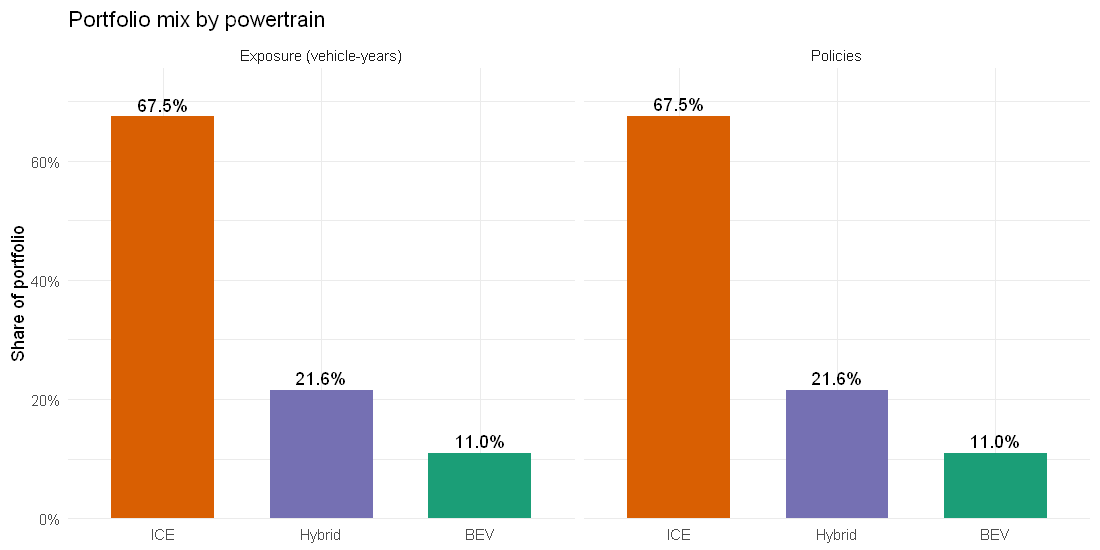

In [9]:
mix |>
  select(Powertrain, `Policies` = policy_share, `Exposure (vehicle-years)` = exposure_share) |>
  pivot_longer(-Powertrain, names_to = "measure", values_to = "share") |>
  ggplot(aes(Powertrain, share, fill = Powertrain)) +
  geom_col(width = 0.65) +
  geom_text(aes(label = percent(share, accuracy = 0.1)), vjust = -0.4) +
  facet_wrap(~ measure) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_continuous(labels = percent, expand = expansion(mult = c(0, 0.12))) +
  labs(title = "Portfolio mix by powertrain",
       x = NULL, y = "Share of portfolio")

### 2.1 Exposure duration
About 89% of policies run a full year. Partial-year policies (cancellations or mid-term starts) contribute only partial exposure, which is why the frequency GLM needs the `log(exposure)` offset.

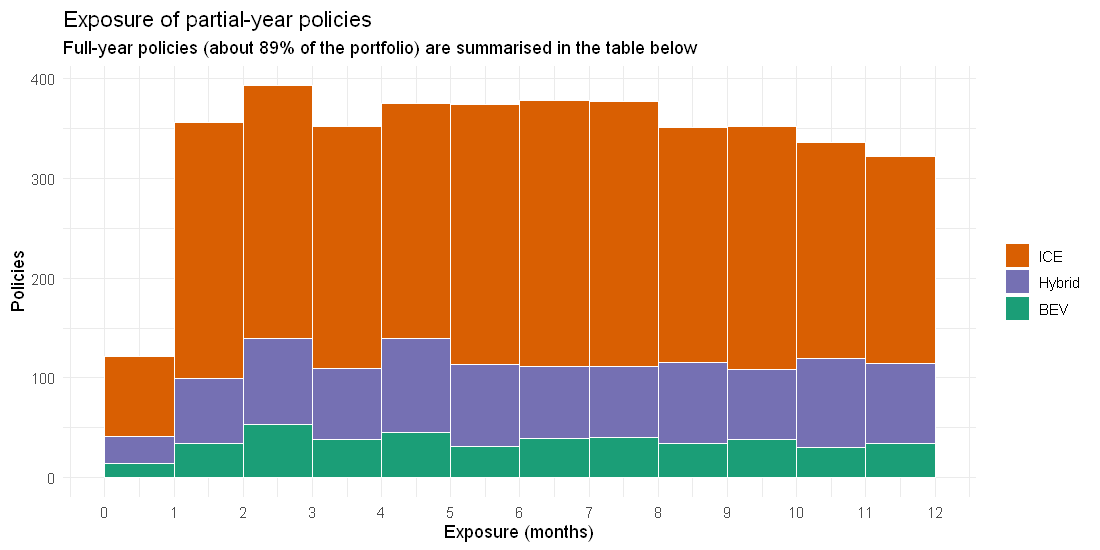

In [10]:
policies |>
  filter(exposure < 0.99) |>
  ggplot(aes(exposure * 12, fill = Powertrain)) +
  geom_histogram(binwidth = 1, boundary = 0, colour = "white") +
  scale_fill_manual(values = pt_colours) +
  scale_x_continuous(breaks = 0:12) +
  scale_y_continuous(labels = comma) +
  labs(title = "Exposure of partial-year policies",
       subtitle = "Full-year policies (about 89% of the portfolio) are summarised in the table below",
       x = "Exposure (months)", y = "Policies", fill = NULL)

In [11]:
policies |>
  group_by(Powertrain) |>
  summarise(full_year_share = percent(mean(exposure >= 0.99), accuracy = 0.1),
            median_months   = number(median(exposure) * 12, accuracy = 0.1))

Powertrain,full_year_share,median_months
<fct>,<chr>,<chr>
ICE,89.3%,12.0
Hybrid,89.2%,12.0
BEV,89.8%,12.0


## 3. Confounder Check 1: Vehicle Characteristics
### 3.1 Vehicle value (sum insured)
*Key check: are BEVs systematically more expensive? A higher sum insured mechanically raises claim severity.*

In [12]:
summarise_by_powertrain(policies, Vehicle_Value) |>
  mutate(across(mean:p75, ~ comma(.x, accuracy = 100, prefix = "₪")))

Powertrain,n,mean,median,p25,p75
<fct>,<int>,<chr>,<chr>,<chr>,<chr>
ICE,25502,"₪66,900","₪59,600","₪37,200","₪88,000"
Hybrid,8251,"₪103,200","₪94,000","₪65,000","₪129,900"
BEV,4193,"₪147,500","₪140,300","₪100,500","₪185,100"


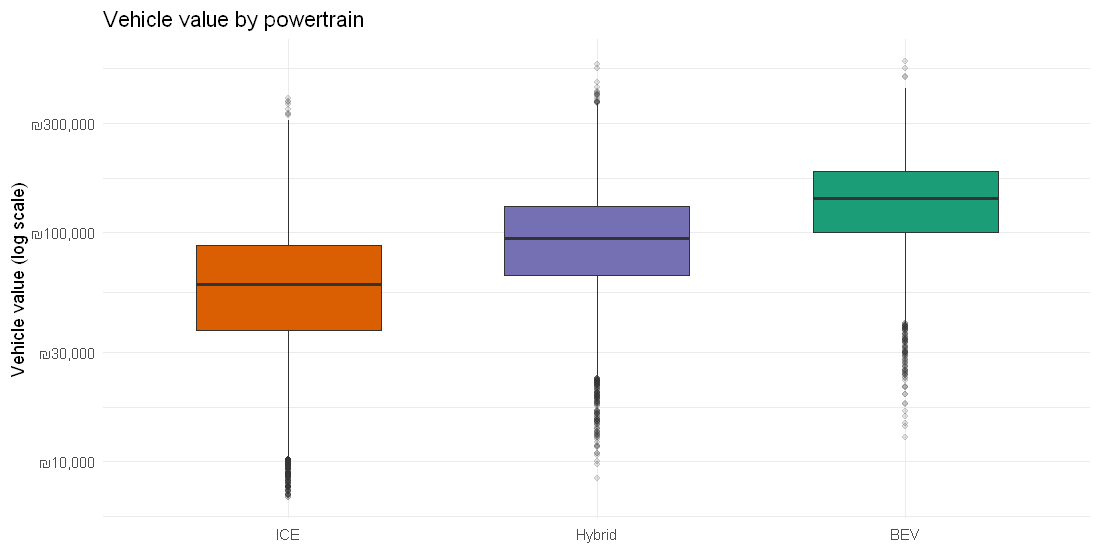

In [13]:
policies |>
  filter(!is.na(Vehicle_Value)) |>
  ggplot(aes(Powertrain, Vehicle_Value, fill = Powertrain)) +
  geom_boxplot(outlier.alpha = 0.15, width = 0.6) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_log10(labels = label_comma(prefix = "₪")) +
  labs(title = "Vehicle value by powertrain",
       x = NULL, y = "Vehicle value (log scale)")

### 3.2 Vehicle age
*Key check: are BEVs substantially newer? Newer cars have higher repair costs and different total-loss behaviour.*

In [14]:
summarise_by_powertrain(policies, Vehicle_Age) |>
  mutate(across(mean:p75, ~ number(.x, accuracy = 0.1)))

Powertrain,n,mean,median,p25,p75
<fct>,<int>,<chr>,<chr>,<chr>,<chr>
ICE,25850,7.5,6.0,4.0,10.0
Hybrid,8263,4.7,4.0,2.0,6.0
BEV,4196,2.2,2.0,1.0,3.0


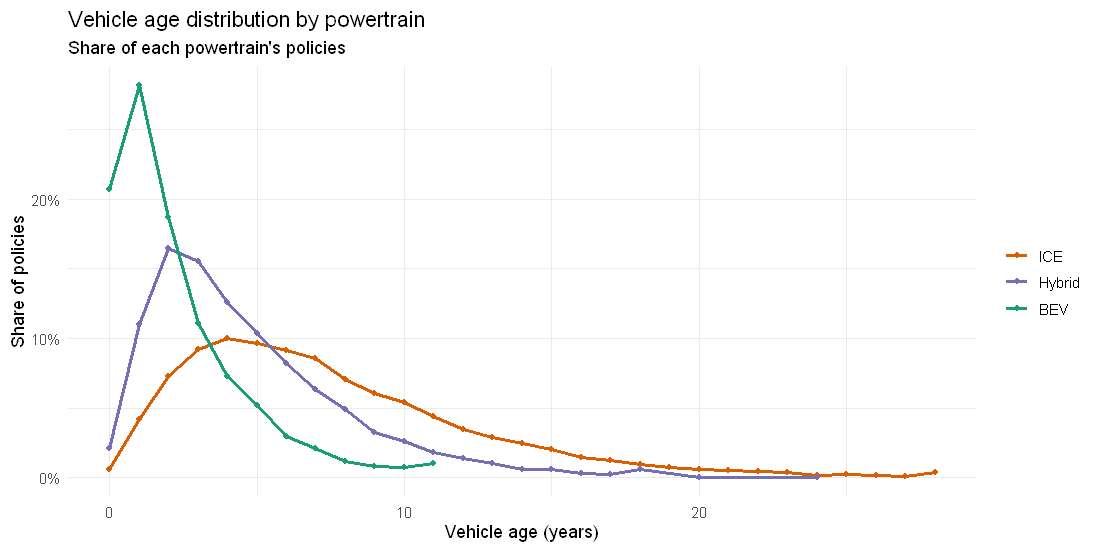

In [15]:
policies |>
  filter(!is.na(Vehicle_Age)) |>
  count(Powertrain, Vehicle_Age) |>
  group_by(Powertrain) |>
  mutate(share = n / sum(n)) |>
  ggplot(aes(Vehicle_Age, share, colour = Powertrain)) +
  geom_line(linewidth = 1) +
  geom_point(size = 1.5) +
  scale_colour_manual(values = pt_colours) +
  scale_y_continuous(labels = percent) +
  labs(title = "Vehicle age distribution by powertrain",
       subtitle = "Share of each powertrain's policies",
       x = "Vehicle age (years)", y = "Share of policies", colour = NULL)

### 3.3 Vehicle segment
The extract has **no body-type or segment field**. Two available proxies:
- **Value tiers** approximate the market segment (economy → luxury). The `NA` row is policies with a missing vehicle value.
- **Fuel_Detail** shows the technology sub-type within each powertrain. After cleaning it is fully consistent with `Powertrain` (the 75 BEV + PHEV conflicts were recoded to Hybrid).

In [16]:
share_table(policies, value_tier)

value_tier,ICE,Hybrid,BEV
<fct>,<chr>,<chr>,<chr>
< 50k,38.8%,13.8%,4.3%
50–100k,41.8%,40.9%,20.3%
100–150k,14.1%,28.8%,31.2%
150–250k,3.8%,14.2%,36.6%
250k+,0.2%,2.1%,7.5%
NA,1.3%,0.1%,0.1%


In [17]:
policies |>
  count(Fuel_Detail, Powertrain) |>
  pivot_wider(names_from = Powertrain, values_from = n, values_fill = 0)

Fuel_Detail,BEV,ICE,Hybrid
<chr>,<int>,<int>,<int>
BEV,4196,0,0
Diesel,0,3599,0
HEV,0,0,6918
PHEV,0,0,1345
Petrol,0,22251,0


## 4. Confounder Check 2: Driver Demographics
### 4.1 Driver age & licence tenure
*Key check: is the EV-adopter demographic skewed (e.g. older and more experienced, or younger)?*

In [18]:
bind_rows(
  `Driver age`     = summarise_by_powertrain(policies, Driver_Age),
  `Licence tenure` = summarise_by_powertrain(policies, License_Tenure),
  .id = "variable"
) |>
  mutate(across(mean:p75, ~ number(.x, accuracy = 0.1)))

variable,Powertrain,n,mean,median,p25,p75
<chr>,<fct>,<int>,<chr>,<chr>,<chr>,<chr>
Driver age,ICE,25424,45.6,46.0,36.0,55.0
Driver age,Hybrid,8138,45.5,46.0,36.0,55.0
Driver age,BEV,4135,45.3,46.0,35.0,56.0
Licence tenure,ICE,25610,26.3,27.0,16.0,36.0
Licence tenure,Hybrid,8181,26.1,27.0,16.0,36.0
Licence tenure,BEV,4154,26.0,26.0,16.0,36.0


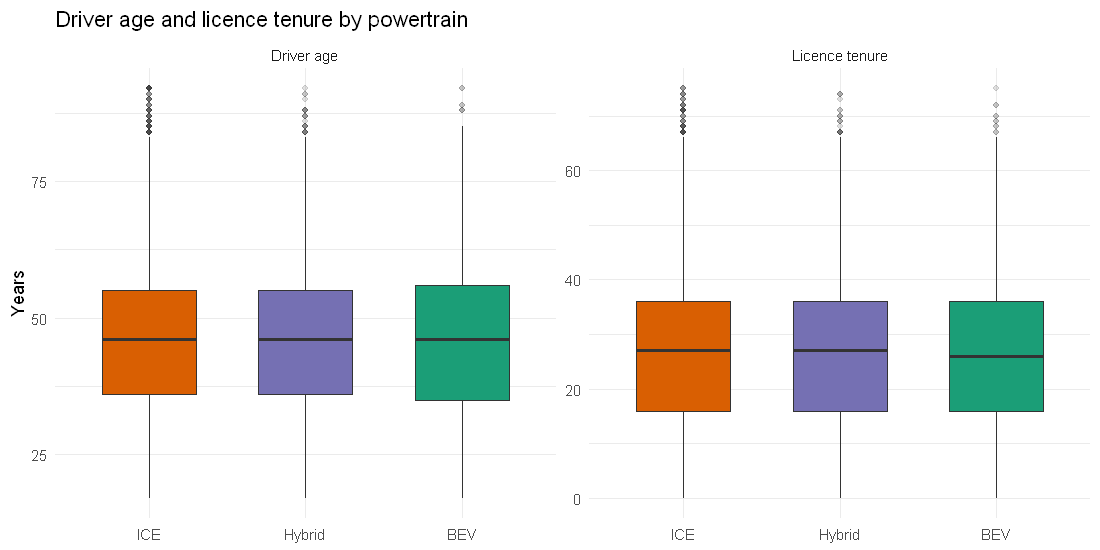

In [19]:
policies |>
  select(Powertrain, `Driver age` = Driver_Age, `Licence tenure` = License_Tenure) |>
  pivot_longer(-Powertrain, names_to = "variable", values_to = "years") |>
  filter(!is.na(years)) |>
  ggplot(aes(Powertrain, years, fill = Powertrain)) +
  geom_boxplot(outlier.alpha = 0.15, width = 0.6) +
  facet_wrap(~ variable, scales = "free_y") +
  scale_fill_manual(values = pt_colours, guide = "none") +
  labs(title = "Driver age and licence tenure by powertrain",
       x = NULL, y = "Years")

### 4.2 Gender & district (share of each powertrain's policies)

In [20]:
share_table(policies, Gender)

Gender,ICE,Hybrid,BEV
<chr>,<chr>,<chr>,<chr>
Female,46.5%,46.0%,46.7%
Male,52.4%,53.0%,52.2%
Unknown,1.1%,1.0%,1.1%


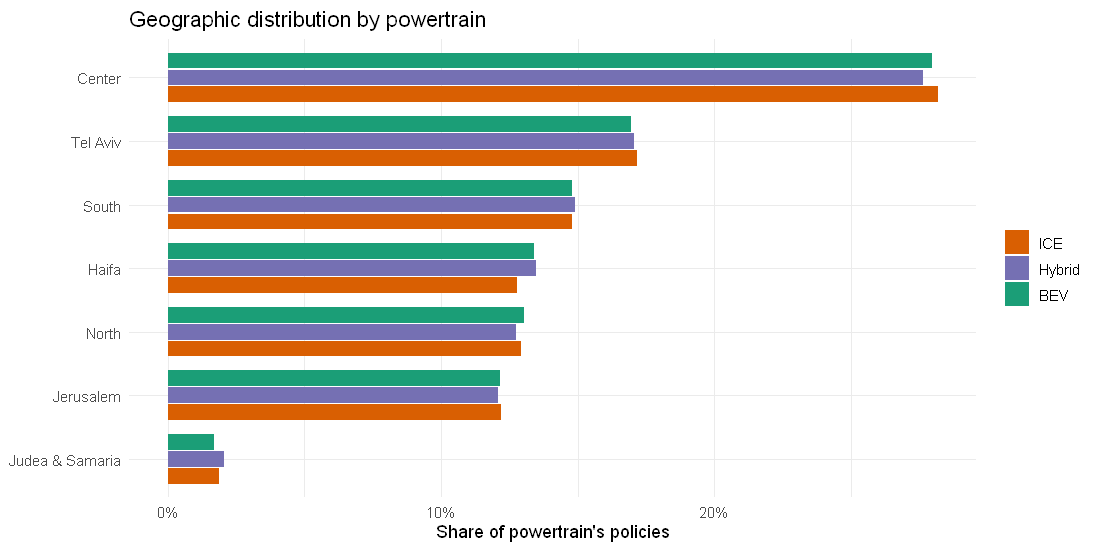

In [21]:
policies |>
  filter(District != "Unknown") |>
  count(Powertrain, District) |>
  group_by(Powertrain) |>
  mutate(share = n / sum(n)) |>
  ungroup() |>
  mutate(District = fct_reorder(District, share, .fun = sum)) |>
  ggplot(aes(share, District, fill = Powertrain)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.75) +
  scale_fill_manual(values = pt_colours) +
  scale_x_continuous(labels = percent) +
  labs(title = "Geographic distribution by powertrain",
       x = "Share of powertrain's policies", y = NULL, fill = NULL)

## 5. Policy Coverage & Pricing Factors
The extract contains **no deductible, voluntary-excess or coverage-type fields**. We assume all policies are the same property-damage product.

The only pricing variable available is the **current premium**. Premium as a share of vehicle value (the *premium rate*) shows whether the existing tariff already charges BEVs differently once the higher sum insured is taken into account.

In [22]:
bind_rows(
  `Premium (₪)`            = summarise_by_powertrain(policies, Premium) |>
                               mutate(across(mean:p75, ~ comma(.x, accuracy = 1))),
  `Premium rate (% value)` = summarise_by_powertrain(policies, premium_rate) |>
                               mutate(across(mean:p75, ~ percent(.x, accuracy = 0.01))),
  .id = "measure"
)

measure,Powertrain,n,mean,median,p25,p75
<chr>,<fct>,<int>,<chr>,<chr>,<chr>,<chr>
Premium (₪),ICE,25829,"3,779","3,506","2,689","4,437"
Premium (₪),Hybrid,8249,"4,778","4,427","3,559","5,452"
Premium (₪),BEV,4191,"5,112","4,794","3,918","5,782"
Premium rate (% value),ICE,25482,7.62%,5.75%,4.38%,8.10%
Premium rate (% value),Hybrid,8237,5.92%,4.56%,3.60%,6.00%
Premium rate (% value),BEV,4188,4.37%,3.34%,2.69%,4.28%


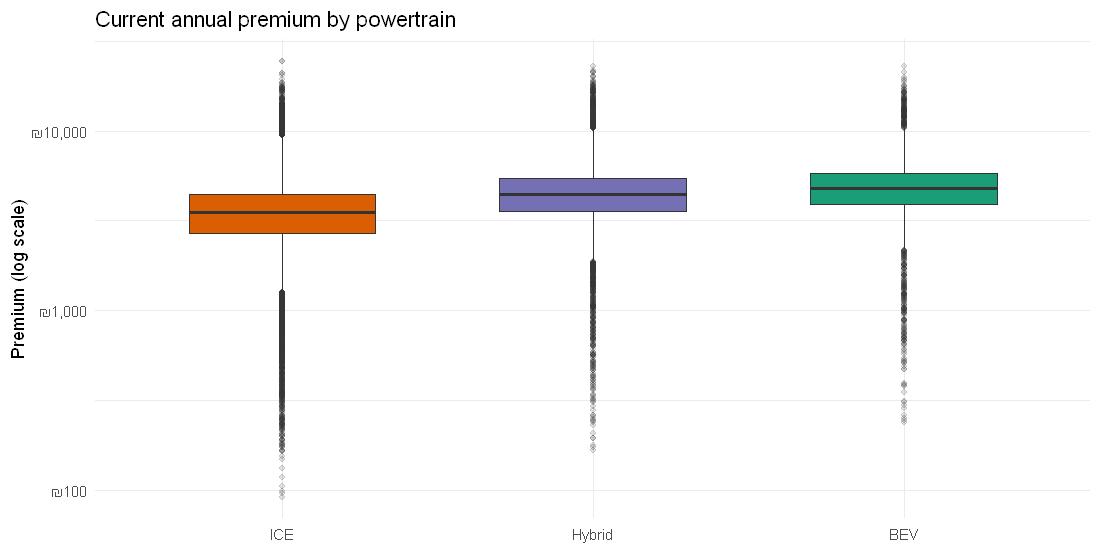

In [23]:
policies |>
  filter(!is.na(Premium)) |>
  ggplot(aes(Powertrain, Premium, fill = Powertrain)) +
  geom_boxplot(outlier.alpha = 0.15, width = 0.6) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_log10(labels = label_comma(prefix = "₪")) +
  labs(title = "Current annual premium by powertrain",
       x = NULL, y = "Premium (log scale)")

## 6. Key Findings & Data Cleaning Summary

*All figures in this notebook are on `data/processed/policies_cleaned.rds`, written by `src/01_clean_datasets.R`. Row counts below come from `data/processed/cleaning_log.csv` (§1.2): raw 38,592 rows → 38,309 policies.*

**Main anomalies in the raw policy data, and how `src/01_clean_datasets.R` handles them**

| Anomaly (rows) | Action | Rationale |
|---|---|---|
| Exact duplicate rows (110) | Drop | They double-count exposure. |
| `dd/mm/yyyy` dates (1,200) · Start > End (59) | Fix: parse both formats; swap the dates back | The formats are unambiguous, and most reversed rows are exact one-year swaps. |
| `1900-01-01` placeholder start (25) | Drop | Exposure is unknown. Left in, these rows move the crude BEV/ICE frequency ratio from 1.06 to 1.15. |
| Overlapping mid-term re-issues (69) + 1 invalid reversed-date re-issue | Drop 69 + 1 rows: collapse each ID to one record over the union period | These are not renewals; keeping both rows double-counts ~48 vehicle-years. |
| Exposure outside (0, 1.01] (0) | Filter kept | The 1.01 limit keeps the 366-day leap-year policies. |
| Label variants: District (440), Gender (1,667), Fuel_Detail (570), `Hybrid ` (209) | Fix: one dictionary; blank / `N/A` / `U` → `Unknown` | Split levels give unstable relativities. |
| Powertrain BEV with Fuel PHEV (75) | Fix → `Hybrid` | A plug-in hybrid has an engine, so it is not a BEV. |
| Driver_Age 999 (65) · Age − Tenure < 17 (85) | Fix → NA; tenure is judged only where age is known | They are placeholders or infeasible values. |
| Vehicle_Age −1 (35) · missing / impossible (0) | Fix → 0; drop (none found) | −1 is a next-model-year registration. |
| BEV with model year < 2012 (78) | Drop | The vintage is infeasible, and age confounds the BEV effect. |
| Value in ₪ thousands (129) · Value 0 (44) | Fix: ×1,000; 0 → NA | All values below 5,000 are plausible as thousands. |
| Premium as text (200) · Premium ≤ 0 (40) | Fix: parse; ≤ 0 → NA | Premium is for reference only, never a rating factor. |

**Key EDA findings**
1. **Portfolio mix.** There are 38,309 policies and 36,331 vehicle-years. BEV makes up 11.0% (3,982 vehicle-years), Hybrid 21.6% and ICE 67.5%. Policy share equals exposure share, and ~89% of policies run a full year in every group. Duration is therefore not a confounder, but the frequency GLM still needs `offset(log(exposure))`.
2. **Vehicle value is the main confounder.** The median value is ₪140k for BEV vs. ₪60k for ICE (≈ 2.35×), and 44% of BEVs are above ₪150k vs. 4% of ICE. → Use `log(Vehicle_Value)` or value tiers in severity / pure premium, and consider the damage ratio.
3. **BEVs are much newer.** The median vehicle age is 2 years for BEV, 4 for Hybrid and 6 for ICE. → Use coarse vehicle-age bands and check VIF, because value, age and powertrain are correlated.
4. **Driver demographics are balanced.** Age (median 46), tenure (26–27), gender (≈ 46.4% F / 52.5% M / 1.1% Unknown) and district differ by ≤ 1 pp across powertrains, so they are ordinary rating factors, not confounders.
5. **The current tariff loads BEVs, but less than in proportion to value.** The median premium is ₪4.8k for BEV vs. ₪3.5k for ICE (+37%), but as a share of value it is 3.34% vs. 5.75%.
- **Modelling decisions:** keep Hybrid as its own level, with ICE as the reference. Coverage, deductible and segment fields are not in the extract.

**Status of the cleaned file**
- `policies_cleaned` has **38,309 rows**, one per `Policy_ID`, and 13 columns. `Powertrain` is a factor (ICE / Hybrid / BEV), and every `exposure` is in (0, 1.01] (§1.3).
- NA is legitimate only in `Driver_Age` (612), `License_Tenure` (364), `Vehicle_Value` (363) and `Premium` (40). District and Gender use an explicit `Unknown` level.
- The file is **not yet joined to claims**. The join and the damage-to-value checks (orphans, in-period claims, OD > 2× value, low-ratio total losses) come in `src/01_etl_merge_and_clean.R`.